# Sequential ADF strategy with **makystats**

This notebook shows how `adf_sequential` automates the classical Dickey–Fuller
decision tree (Model 3 → Φ₃ / Φ₂ → Model 2 → Φ₁ → Model 1), while keeping every
intermediate regression and joint test **auditable**.

**Data**

| Series | Source | Role in the notebook |
|--------|--------|----------------------|
| US real GDP | `us_macro_quarterly.csv` | I(1) with drift — long path with Φ tests |
| US unemployment | same file | I(0) around a non-zero mean |
| US CPI | same file | I(1) with drift — *short* path (Model 3 only) |
| Simulated DS + trend in Δy | controlled DGP | Illustrates branch (ii-b): `Δy = c + b·t + e` |

ADF critical values: MacKinnon (2010). Joint Φ critical values: Dickey–Fuller (1981).

Quarterly macro series are used on purpose (no strong monthly seasonality), so the
zero-frequency unit-root strategy is the appropriate tool.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from makystats.stationarity_test import adf, adf_sequential

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.titlesize"] = 12

## 1. Load example macro data

In [2]:
us = pd.read_csv("../ARDL/data/us_macro_quarterly.csv")
us.index = pd.to_datetime(
    [f"{int(y)}-{int(q)*3:02d}-01" for y, q in zip(us["year"], us["quarter"])]
)
us = us.sort_index()

realgdp = us["realgdp"].astype(float)
unemp = us["unemp"].astype(float)
cpi = us["cpi"].astype(float)

print("sample:", realgdp.index.min().date(), "→", realgdp.index.max().date())
print(f"n = {len(realgdp)} quarters")

sample: 1959-03-01 → 2009-09-01
n = 203 quarters


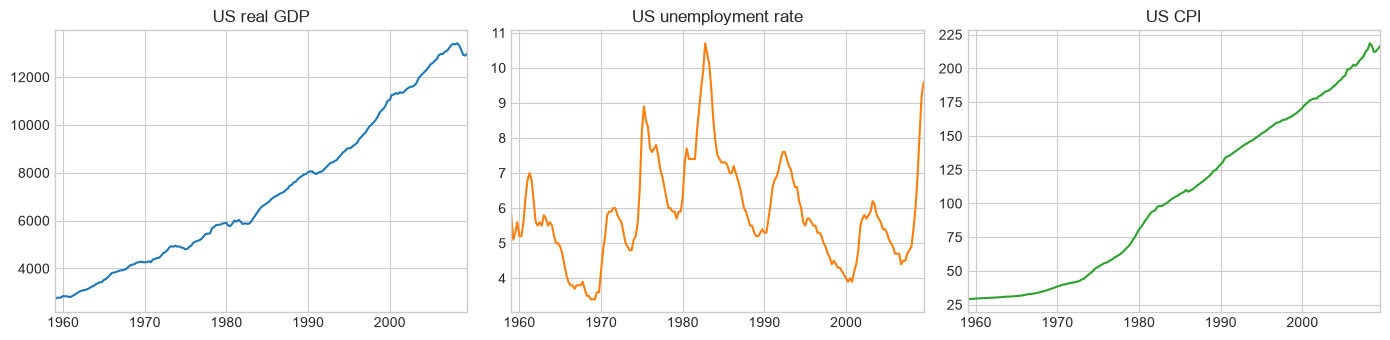

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
realgdp.plot(ax=axes[0], title="US real GDP", color="C0", legend=False)
unemp.plot(ax=axes[1], title="US unemployment rate", color="C1", legend=False)
cpi.plot(ax=axes[2], title="US CPI", color="C2", legend=False)
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
plt.show()

## 2. One line vs the full DF tree

The classical strategy requires choosing deterministic terms (none / const / trend),
running joint Φ tests, and branching. With makystats this is a single call:


In [5]:
res_gdp = adf_sequential(realgdp, alpha=0.05)
print(res_gdp.summary())

Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 14
  nobs       : 188
  final model: c
  conclusion : I(1) with drift
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -1.25251
        pvalue: 0.899179
        reject_unit_root: False
        coef_trend: 0.685426
        t_trend: 1.60645
        coef_const: 43.9502
        t_const: 2.37788
    (2) Model 3: joint Phi3 H0: (rho, b) = (0, 0)
        phi3: 2.24095
        cv: 6.402
        critical_values: {'1%': 8.554, '5%': 6.401999999999999, '10%': 5.423066666666666}
        reject_phi3: False
        joint: <use path[1]['joint'].summary()>
    (3) Model 3 (ii-a): joint Phi2 H0: (rho, c, b) = (0, 0, 0)
        phi2: 4.17056
        cv: 4.80373
        critical_values: {'1%': 6.335733333333334, '5%': 4.803733333333334, '10%': 4.107200000000001}
        reject_phi2: False
        joint: <use path[2]['joint'].summary()>
    (4) Model 3: Phi2 accepted — continue to Model 2
    (5) Model 2 (co

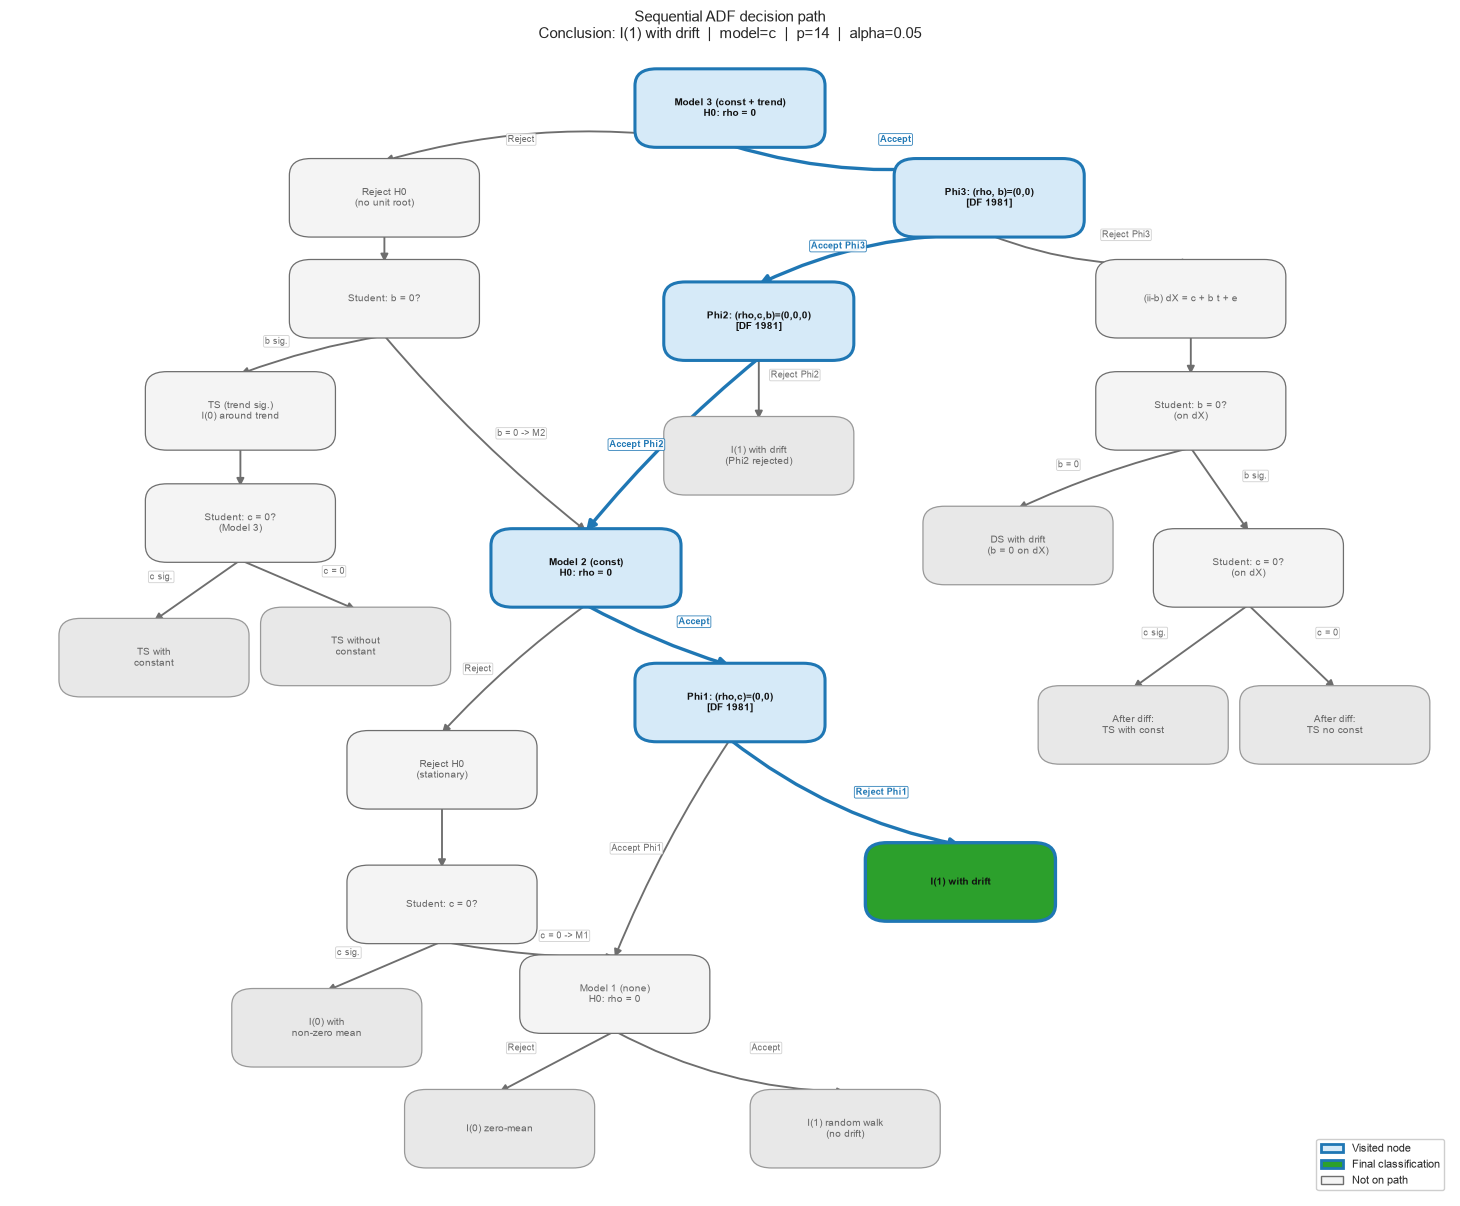

In [6]:
# Decision-tree plot (active path highlighted)
fig, ax = res_gdp.plot()
plt.show()

### Interpretation (real GDP)

1. **Model 3 (ct)** — unit-root τ does **not** reject → maintain H₀: ρ = 0.
2. **Φ₃** (ρ = b = 0) is **not** rejected → no joint evidence of trend-stationarity.
3. **Φ₂** (ρ = c = b = 0) is **not** rejected → move to Model 2.
4. **Model 2 (c)** — unit root still not rejected.
5. **Φ₁** (ρ = c = 0) **is** rejected → constant matters under the unit-root null.

**Conclusion:** *I(1) with drift* — difference-stationary growth. First differences
are the natural transformation before VAR / ARIMA work on GDP.


## 3. Transparency — every node is recoverable

`adf_sequential` does not hide intermediate fits. You can reproduce any step with the
same lag length as the sequential path.


In [24]:
# Model 3 summary ≡ adf(..., regression="ct") at the same lag
print(res_gdp.adf_model(3).summary()), print()
print(res_gdp.adf_model(3).regression.summary()), print()                  # Pure ADF OLS table for Model 3 (coef / se / t)
ref = adf(realgdp, maxlag=res_gdp.lags, regression="ct", autolag=None)
print("Match vs standalone adf(ct):",
      abs(res_gdp.adf_model(3).statistic - ref.statistic) < 1e-10)

ADF (Augmented Dickey–Fuller)
  regspec        : ct
  statistic      : -1.25251
  p-value        : 0.899179
  lags           : 14
  nobs           : 188
  H0             : unit root (series is I(1) / non-stationary)
  H1             : no unit root (stationary around the specified deterministic terms)
  critical values: 1%: -4.0077, 10%: -3.1409, 5%: -3.4341
  engine: native
  source: adf_sequential

                            ADF Regression Results                            
Dep. Variable:    D.y                     R-squared:          0.298
Model:            ADF-OLS (ct)            Adj. R-squared:     0.233
Method:           Least Squares           F-statistic:        4.542
No. Observations: 188                     Prob (F-statistic): 1.658e-07
Df Residuals:     171                     Log-Likelihood:     -1006.708
Df Model:         16                      AIC:                1514
                                          BIC:                1569
                  coef   std err    

In [14]:
# Joint Φ3 (+ restricted / unrestricted OLS tables)
print(res_gdp.joint("phi3").summary()), print()
print(res_gdp.joint("phi3").restricted.summary())

                         Joint ADF test  PHI3                         
H0 restriction     : (rho, b) = (0, 0)
Model              : ADF ct
Lags (Delta terms) : 14
No. Observations   : 188
q (restrictions)   : 2
SSR unrestricted   : 492983
SSR restricted     : 505904
Phi statistic      : 2.24095
Critical values (Dickey-Fuller 1981):
    1% : 8.5540
    5% : 6.4020
   10% : 5.4231
Decision @ 5%: do not reject H0
----------------------------------------------------------------------
Access OLS tables:
  result.unrestricted.summary()  # full ADF regression
  result.restricted.summary()    # under H0

Joint ADF  PHI3  — restricted under H0
H0: (rho, b) = (0, 0)
Model: ADF ct  |  lags: 14  |  nobs: 188
Note: Phi critical values are Dickey-Fuller (1981), not Fisher F.

                            ADF Regression Results                            
Dep. Variable:    D.y                     R-squared:          0.280
Model:            ADF restricted phi3     Adj. R-squared:     0.222
Method:      

In [25]:
# Model 2
print(res_gdp.adf_model(2).summary()), print()
print(res_gdp.adf_model(2).regression.summary())

ADF (Augmented Dickey–Fuller)
  regspec        : c
  statistic      : 1.37256
  p-value        : 0.996986
  lags           : 14
  nobs           : 188
  H0             : unit root (series is I(1) / non-stationary)
  H1             : no unit root (stationary around the specified deterministic terms)
  critical values: 1%: -3.4656, 10%: -2.5750, 5%: -2.8770
  engine: native
  source: adf_sequential

                            ADF Regression Results                            
Dep. Variable:    D.y                     R-squared:          0.288
Model:            ADF-OLS (c)             Adj. R-squared:     0.226
Method:           Least Squares           F-statistic:        4.63
No. Observations: 188                     Prob (F-statistic): 2.101e-07
Df Residuals:     172                     Log-Likelihood:     -1008.116
Df Model:         15                      AIC:                1515
                                          BIC:                1566
                  coef   std err       

In [26]:
# Joint Φ1 (+ restricted / unrestricted OLS tables)
print(res_gdp.joint("phi1").summary()), print()
print(res_gdp.joint("phi1").restricted.summary())

                         Joint ADF test  PHI1                         
H0 restriction     : (rho, c) = (0, 0)
Model              : ADF c
Lags (Delta terms) : 14
No. Observations   : 188
q (restrictions)   : 2
SSR unrestricted   : 500423
SSR restricted     : 529053
Phi statistic      : 4.92029
Critical values (Dickey-Fuller 1981):
    1% : 6.4020
    5% : 4.6631
   10% : 4.0107
Decision @ 5%: reject H0 (joint restriction fails)
----------------------------------------------------------------------
Access OLS tables:
  result.unrestricted.summary()  # full ADF regression
  result.restricted.summary()    # under H0

Joint ADF  PHI1  — restricted under H0
H0: (rho, c) = (0, 0)
Model: ADF c  |  lags: 14  |  nobs: 188
Note: Phi critical values are Dickey-Fuller (1981), not Fisher F.

                            ADF Regression Results                            
Dep. Variable:    D.y                     R-squared:          0.247
Model:            ADF restricted phi1     Adj. R-squared:     0.

## 4. Contrast A — unemployment (stationary around a mean)

Same API; the path **stops earlier** once the unit root is rejected in Model 2.


In [27]:
res_un = adf_sequential(unemp, alpha=0.05)
print(res_un.summary())

Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 2
  nobs       : 200
  final model: c
  conclusion : I(0) with non-zero mean
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -2.89714
        pvalue: 0.163142
        reject_unit_root: False
        coef_trend: 0.000222869
        t_trend: 0.728094
        coef_const: 0.20283
        t_const: 2.44301
    (2) Model 3: joint Phi3 H0: (rho, b) = (0, 0)
        phi3: 4.45998
        cv: 6.39
        critical_values: {'1%': 8.53, '5%': 6.390000000000001, '10%': 5.416666666666666}
        reject_phi3: False
        joint: <use path[1]['joint'].summary()>
    (3) Model 3 (ii-a): joint Phi2 H0: (rho, c, b) = (0, 0, 0)
        phi2: 3.03423
        cv: 4.79333
        critical_values: {'1%': 6.3133333333333335, '5%': 4.793333333333333, '10%': 4.1000000000000005}
        reject_phi2: False
        joint: <use path[2]['joint'].summary()>
    (4) Model 3: Phi2 accepted — continue to Model 2
    (5) 

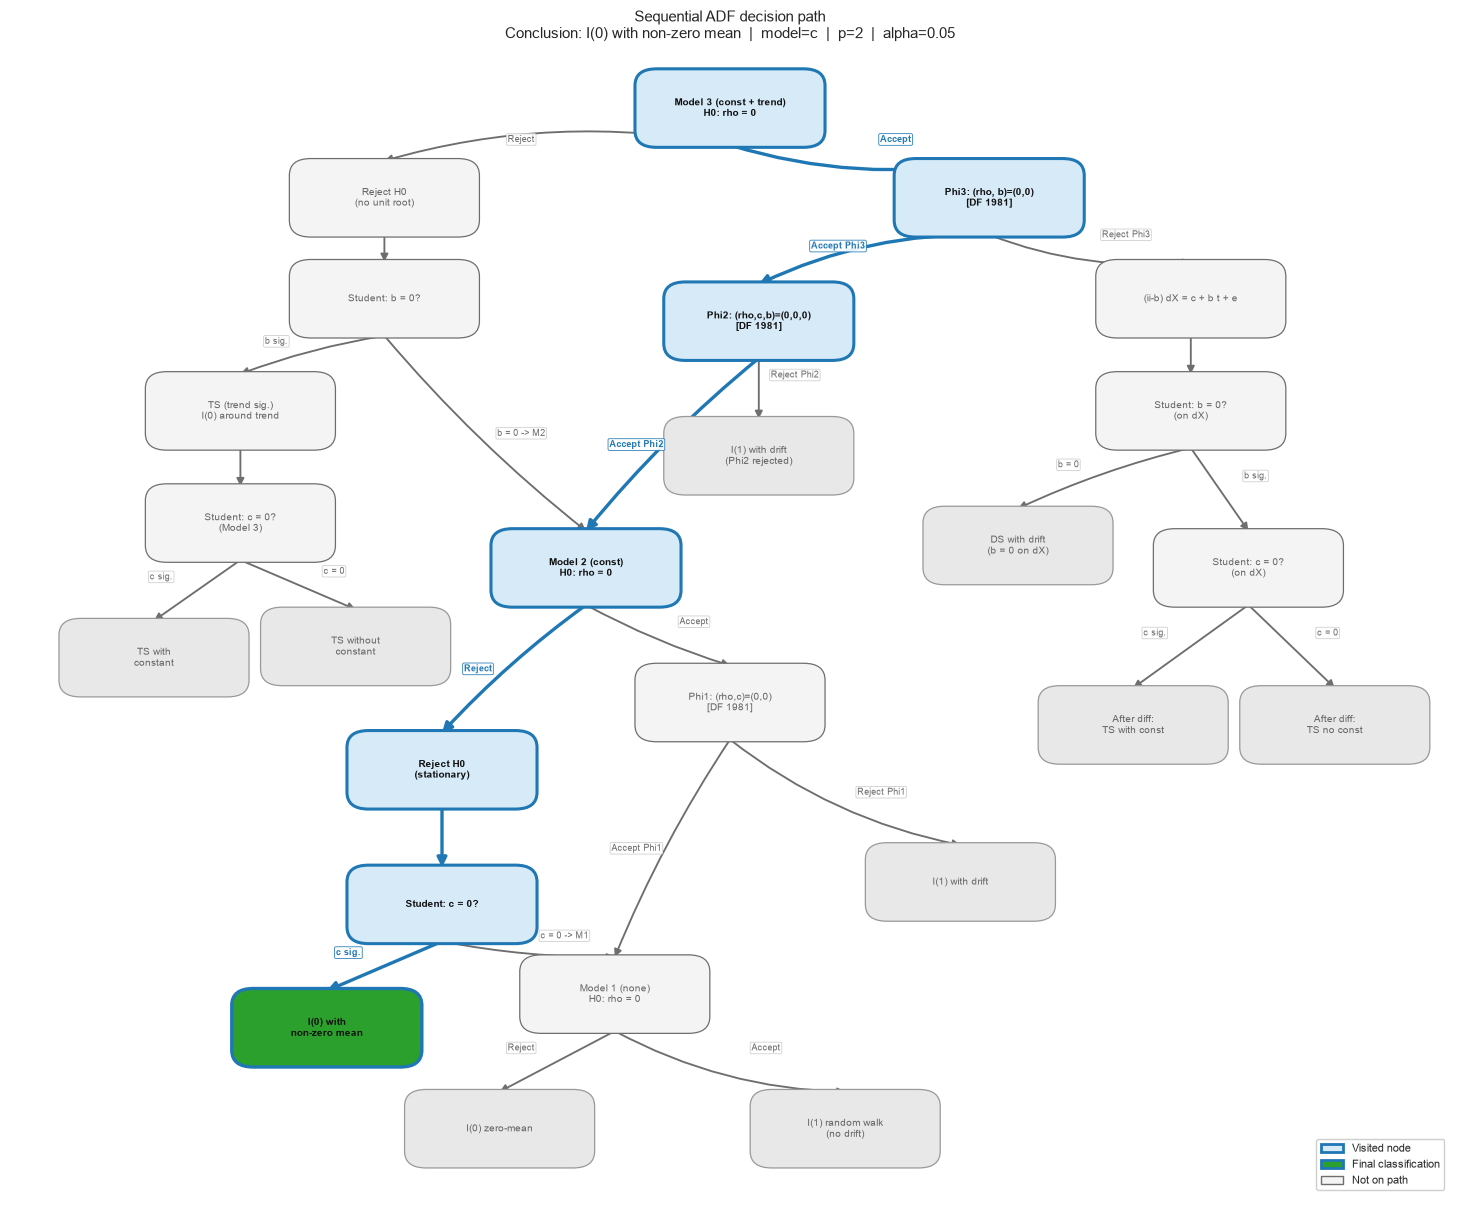

In [28]:
fig, ax = res_un.plot()
plt.show()

### Interpretation (unemployment)

- In Model 3 the unit root is **rejected**.
- The trend coefficient is then tested (Student approximation under stationarity)
  and is **not** significant → the trend was unnecessary.
- Model 2 rejects the unit root; the constant is significant.

**Conclusion:** *I(0) with non-zero mean* — levels (not differences) are appropriate
for many empirical designs on this sample.


In [30]:
print(res_un.adf_model(2).summary()), print()
print(res_un.adf_model(2).regression.summary())

ADF (Augmented Dickey–Fuller)
  regspec        : c
  statistic      : -2.9
  p-value        : 0.0453479
  lags           : 2
  nobs           : 200
  H0             : unit root (series is I(1) / non-stationary)
  H1             : no unit root (stationary around the specified deterministic terms)
  critical values: 1%: -3.4635, 10%: -2.5745, 5%: -2.8761
  engine: native
  source: adf_sequential

                            ADF Regression Results                            
Dep. Variable:    D.y                     R-squared:          0.477
Model:            ADF-OLS (c)             Adj. R-squared:     0.469
Method:           Least Squares           F-statistic:        59.66
No. Observations: 200                     Prob (F-statistic): 0
Df Residuals:     196                     Log-Likelihood:     -3.742
Df Model:         3                       AIC:                -552.1
                                          BIC:                -538.9
                  coef   std err        t    P>|

## 5. Contrast B — US CPI (short path)

A price level that never leaves Model 3: Φ₂ is rejected, so the procedure classifies
**I(1) with drift** without estimating Model 2 / Model 1.


In [32]:
res_cpi = adf_sequential(cpi, alpha=0.05)
print(res_cpi.summary())

Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 12
  nobs       : 190
  final model: ct
  conclusion : I(1) with drift (Phi2 rejected)
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -3.17976
        pvalue: 0.0885116
        reject_unit_root: False
        coef_trend: 0.0293852
        t_trend: 3.32046
        coef_const: 0.463135
        t_const: 3.33013
    (2) Model 3: joint Phi3 H0: (rho, b) = (0, 0)
        phi3: 5.79498
        cv: 6.4
        critical_values: {'1%': 8.55, '5%': 6.4, '10%': 5.422}
        reject_phi3: False
        joint: <use path[1]['joint'].summary()>
    (3) Model 3 (ii-a): joint Phi2 H0: (rho, c, b) = (0, 0, 0)
        phi2: 6.21494
        cv: 4.802
        critical_values: {'1%': 6.332, '5%': 4.802, '10%': 4.106}
        reject_phi2: True
        joint: <use path[2]['joint'].summary()>


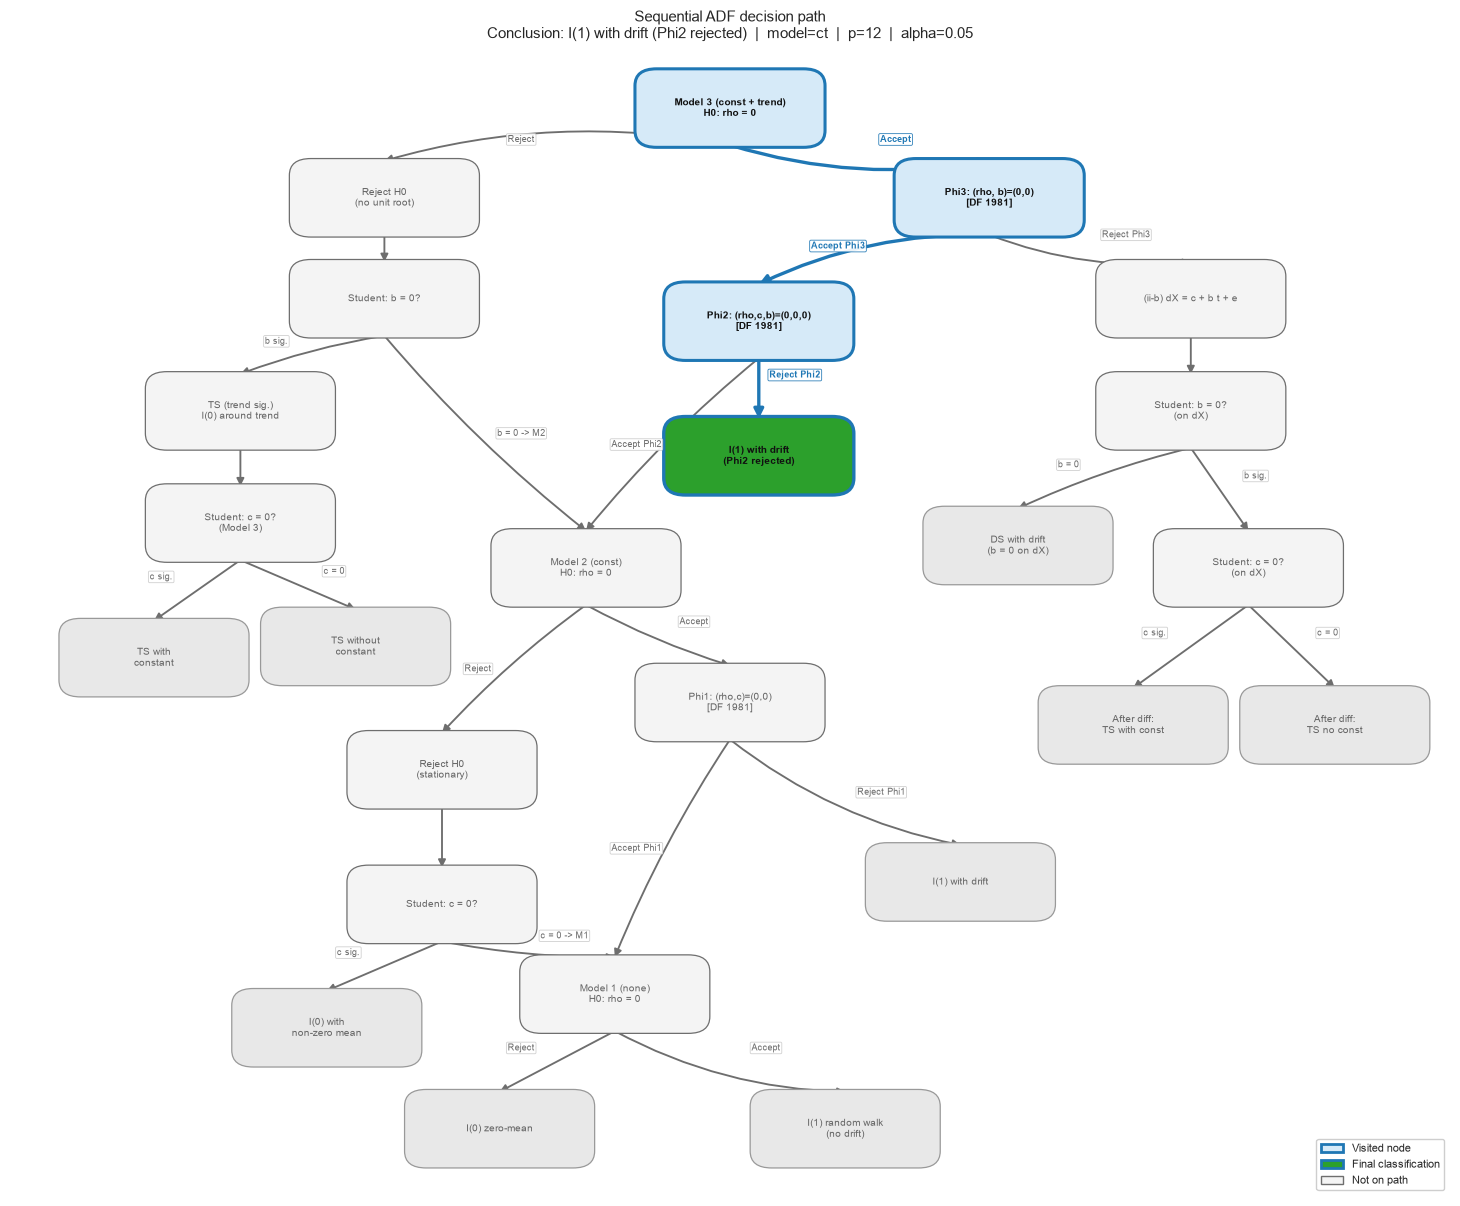

In [33]:
fig, ax = res_cpi.plot()
plt.show()

### Interpretation (CPI)

- Model 3 does not reject ρ = 0 (unit root kept).
- Φ₃ is not rejected; **Φ₂ is rejected** → under the DF strategy this points to a
  **drift** under the unit-root null.
- Only `model3` is stored (`res_cpi.adf_model(2)` would raise `KeyError`).

**Conclusion:** *I(1) with drift*. Working with inflation (Δ log CPI or Δ CPI) is the
usual next step — consistent with treating the price *level* as difference-stationary.


In [34]:
print(res_cpi.adf_model(3).summary())
print()
print(res_cpi.joint("phi2").summary())

ADF (Augmented Dickey–Fuller)
  regspec        : ct
  statistic      : -3.17976
  p-value        : 0.0885116
  lags           : 12
  nobs           : 190
  H0             : unit root (series is I(1) / non-stationary)
  H1             : no unit root (stationary around the specified deterministic terms)
  critical values: 1%: -4.0072, 10%: -3.1408, 5%: -3.4339
  engine: native
  source: adf_sequential

                         Joint ADF test  PHI2                         
H0 restriction     : (rho, c, b) = (0, 0, 0)
Model              : ADF ct
Lags (Delta terms) : 12
No. Observations   : 190
q (restrictions)   : 3
SSR unrestricted   : 97.7055
SSR restricted     : 108.115
Phi statistic      : 6.21494
Critical values (Dickey-Fuller 1981):
    1% : 6.3320
    5% : 4.8020
   10% : 4.1060
Decision @ 5%: reject H0 (joint restriction fails)
----------------------------------------------------------------------
Access OLS tables:
  result.unrestricted.summary()  # full ADF regression
  result.re

## 6. Controlled simulation — unit root with drift *and* trend in Δy

To illustrate branch **(ii-b)** of the sequential strategy, simulate:

$$
y_t = y_{t-1} + c + \beta\, t + \varepsilon_t
$$

so the first difference has both a constant and a linear trend. After Φ₃ is rejected
while the unit-root null is maintained, the procedure fits `Δy = c + b·t + e` to
refine the description of the DS process.


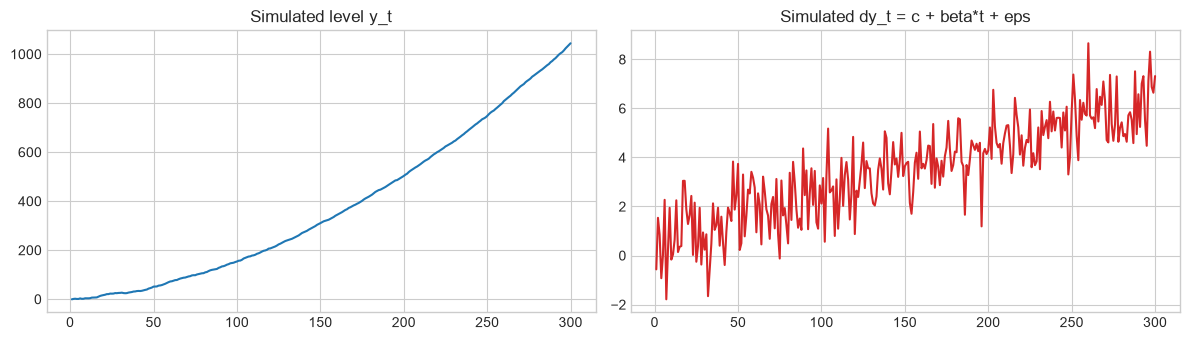

In [35]:
np.random.seed(123)

T = 300
c = 0.5       # constant in Δy
beta = 0.02   # trend slope in Δy
sigma = 1.0

t = np.arange(1, T + 1)
eps = np.random.normal(0, sigma, T)

# Unit root + constant + linear trend in the difference:
# y_t = y_{t-1} + c + beta*t + eps_t
dy = c + beta * t + eps
y_sim = np.cumsum(dy)
serie = pd.Series(y_sim, index=t, name="y")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
serie.plot(ax=axes[0], title="Simulated level y_t", color="C0", legend=False)
pd.Series(dy, index=t).plot(
    ax=axes[1],
    title="Simulated dy_t = c + beta*t + eps",
    color="C3",
    legend=False,
)
fig.tight_layout()
plt.show()

In [36]:
res_sim = adf_sequential(serie, maxlag=10, autolag="AIC", alpha=0.05)
print(res_sim.summary())

Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 0
  nobs       : 299
  final model: ct
  conclusion : I(1) with drift; after differencing, TS with constant (trend significant in dX)
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -0.497677
        pvalue: 0.983525
        reject_unit_root: False
        coef_trend: 0.0208081
        t_trend: 6.19828
        coef_const: 0.549669
        t_const: 3.0121
    (2) Model 3: joint Phi3 H0: (rho, b) = (0, 0)
        phi3: 387.025
        cv: 6.33216
        critical_values: {'1%': 8.41236, '5%': 6.33216, '10%': 5.38412}
        reject_phi3: True
        joint: <use path[1]['joint'].summary()>
    (3) Model 3 (ii-b): Phi3 rejected — regress dX = c + b*t + e
        t_trend: 27.8526
        pvalue_trend_approx: 0
        trend_significant: True
        t_const: 5.19098
        pvalue_const_approx: 3.88626e-07
        const_significant: True
        note: Under unit-root null, Student critical v

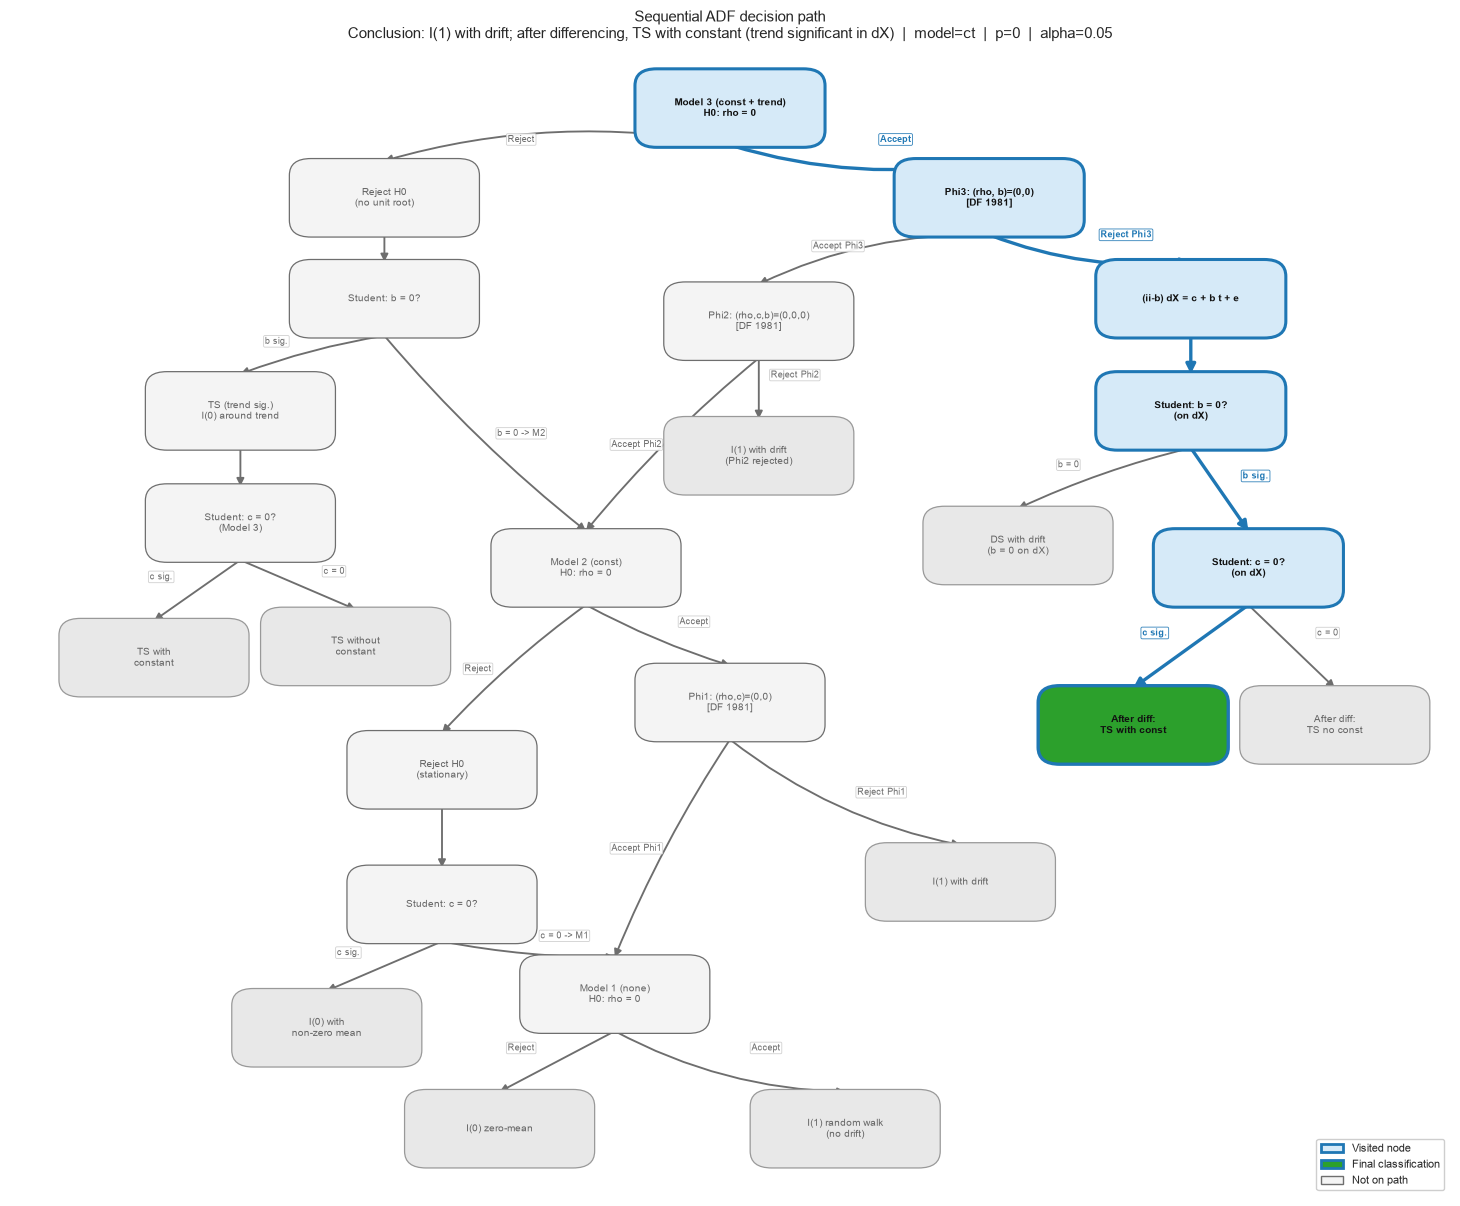

In [37]:
fig, ax = res_sim.plot()
plt.show()

### Walk the (ii-b) node

When Φ₃ is rejected but the unit root is kept, the path stores the auxiliary
regression $\Delta y = c + b\cdot t + e\$ :


In [40]:
# Locate the dx_regression step on the path
for i, step in enumerate(res_sim.path):
    if "dx_regression" in step:
        print(f"path[{i}]: {step.get('step', '')}")
        print(step["dx_regression"].summary())
        break
else:
    print("No (ii-b) dx_regression on this path (branch not reached).")

path[2]: Model 3 (ii-b): Phi3 rejected — regress dX = c + b*t + e
                      (ii-b)  D.y = c + b*t + e                       
Context : after rejecting Phi3 in sequential ADF
H0 path : unit root maintained; this refines DS description
No. Observations : 299
t_const  (Student, approx.) : 5.1910
P>|t| const (approx.)       : 3.886e-07
t_trend  (Student, approx.) : 27.8526
P>|t| trend (approx.)       : 0
----------------------------------------------------------------------
Notes:
[1] Under the unit-root null, Student critical values for c and b
    are approximate (non-standard distributions).
[2] Full OLS table: result.regression.summary()  or  result.ols.summary()
                            ADF Regression Results                            
Dep. Variable:    D.y                     R-squared:          0.723
Model:            D.y = c + b*t           Adj. R-squared:     0.722
Method:           Least Squares           F-statistic:        775.8
No. Observations: 299            

In [41]:
print(res_sim.adf_model(3).summary())
print()
print(res_sim.joint("phi3").summary())

ADF (Augmented Dickey–Fuller)
  regspec        : ct
  statistic      : -0.497677
  p-value        : 0.983525
  lags           : 0
  nobs           : 299
  H0             : unit root (series is I(1) / non-stationary)
  H1             : no unit root (stationary around the specified deterministic terms)
  critical values: 1%: -3.9894, 10%: -3.1357, 5%: -3.4253
  engine: native
  source: adf_sequential

                         Joint ADF test  PHI3                         
H0 restriction     : (rho, b) = (0, 0)
Model              : ADF ct
Lags (Delta terms) : 0
No. Observations   : 299
q (restrictions)   : 2
SSR unrestricted   : 313.233
SSR restricted     : 1132.35
Phi statistic      : 387.025
Critical values (Dickey-Fuller 1981):
    1% : 8.4124
    5% : 6.3322
   10% : 5.3841
Decision @ 5%: reject H0 (joint restriction fails)
----------------------------------------------------------------------
Access OLS tables:
  result.unrestricted.summary()  # full ADF regression
  result.restricted

### Interpretation (simulation)

Under the true DGP, \(y_t\) is **difference-stationary** with a trending drift.
The sequential procedure should:

- keep the unit-root null in Model 3,
- **reject Φ₃** (because a trend in \(\Delta y\) makes \((ho, b) = (0, 0)\) false
  in the ADF levels regression in a detectable way for this design),
- expose the **(ii-b)** regression \(\Delta y = c + b\cdot t + e\) for inspection.

That is precisely the branch that a manual DF strategy would take — here recovered
automatically and open to audit via `path[i]["dx_regression"]`.


## 7. Side-by-side summary


In [42]:
rows = []
for name, res in [
    ("US real GDP", res_gdp),
    ("US unemployment", res_un),
    ("US CPI", res_cpi),
    ("Simulation (DS + trend in Δy)", res_sim),
]:
    rows.append({
        "series": name,
        "nobs": res.nobs,
        "lags": res.lags,
        "final model": res.model,
        "models on path": ", ".join(sorted(res._models)),
        "conclusion": res.conclusion,
    })
summary_table = pd.DataFrame(rows).set_index("series")
summary_table

,nobs,lags,final model,models on path,conclusion
series,,,,,
US real GDP,188,14,c,"model2, model3",I(1) with drift
US unemployment,200,2,c,"model2, model3",I(0) with non-zero mean
US CPI,190,12,ct,model3,I(1) with drift (Phi2 rejected)
Simulation (DS + trend in Δy),299,0,ct,model3,"I(1) with drift; after differencing, TS with c..."


## 8. Takeaways

1. **One call** runs the full DF sequential strategy at a common lag length.
2. **Different series, different trees** — GDP (long I(1)+drift path), unemployment
   (I(0)+mean), CPI (short I(1)+drift path), simulation ((ii-b) branch).
3. **Nothing is a black box**: `adf_model`, `joint`, `path[i]["dx_regression"]`
   and `.regression.summary()` expose the same objects you would build by hand.
4. Critical values follow **MacKinnon (2010)** for τ and **Dickey–Fuller (1981)** for Φ.

```python
from makystats.stationarity_test import adf_sequential
res = adf_sequential(y)
print(res.summary())
res.plot()
```
